# Counting the universal set

*The vignette `vignette("universal-set")` of the R package clobe, ported to `psp.clobe`.*

To judge whether a model is too flexible, we need to know how many ordinal patterns *could* have been observed. This set of all possible patterns is the **universal set**, and its size is the `universal` argument of `gdistance()`. This notebook explains how to count it. It assumes you know what an inequality matrix is; if not, start with [inequality-matrices.ipynb](inequality-matrices.ipynb).

`psp.clobe` gives three ways to get at the universal set:

| Tool | What it gives | Use it when |
|---|---|---|
| `fubini()`, `semiorders()` | the number of patterns, instantly | any pattern could be measured |
| `orderings()` | every pattern, as matrices | you need the patterns themselves |
| `brutes()` | the patterns a particular measurement scale can produce | the scale is coarse compared with the threshold |

In [1]:
import sys

import math
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from psp import clobe

sys.path.insert(0, "..")  # for notebooks/figure_style.py
from figure_style import aqua, blue, figures, ink, light, muted, orange, reference, titled

show = figures("clobe-universal-set")


## Building block: splitting stimuli into groups

How many ways are there to split $n$ stimuli into $k$ groups, where the groups have no order and none is empty? This is the **Stirling number of the second kind**, $S(n, k)$. For example, 3 stimuli can be split into 2 groups in 3 ways: {1, 2}{3}, {1, 3}{2} and {2, 3}{1}.

In [2]:
clobe.stirling2(3, 2)

3

There is a simple way to compute them. Take the last stimulus. Either it is in a group of its own, and the other $n - 1$ stimuli form the remaining $k - 1$ groups; or it joins one of the $k$ groups formed by the others. So

$$
S(n, k) = S(n-1, k-1) + k \, S(n-1, k), \qquad S(0, 0) = 1.
$$

This is the standard recurrence of the Stirling numbers of the second kind (Graham, Knuth & Patashnik, 1994, chap. 6; OEIS A008277), and the one `stirling2()` uses.

In [3]:
pd.DataFrame([[clobe.stirling2(n, k) for k in range(1, 7)] for n in range(1, 7)],
             index=pd.Index(range(1, 7), name="n"), columns=pd.Index(range(1, 7), name="k"))

k,1,2,3,4,5,6
n,,,,,,
1,1,0,0,0,0,0
2,1,1,0,0,0,0
3,1,3,1,0,0,0
4,1,7,6,1,0,0
5,1,15,25,10,1,0
6,1,31,90,65,15,1


## Weak orderings: the Fubini numbers

With `ordering="weak"`, only exact ties are "about the same", and a pattern is a ranking with ties. To build one, split the $n$ stimuli into $j$ tied groups ($S(n, j)$ ways) and rank the groups from top to bottom ($j!$ ways). Adding up over the possible numbers of groups gives the **Fubini numbers** (also called ordered Bell numbers; OEIS A000670):

$$
a(n) = \sum_{j=1}^{n} j! \, S(n, j).
$$

For 3 stimuli: one group (all tied) in 1 way; two groups in $2! \times 3 = 6$ ways; three groups (no ties) in $3! = 6$ ways. That makes 13.

In [4]:
[clobe.fubini(n) for n in range(1, 9)]

[1, 3, 13, 75, 541, 4683, 47293, 545835]

If the dependent variable can take fewer distinct values than there are stimuli, there cannot be more tied groups than values. `levels` stops the sum there:

In [5]:
clobe.fubini(4, levels=3)  # 4 stimuli, but only 3 possible values

51

## Semiorders

With the default `ordering="semiorder"`, stimuli within the threshold of each other are "about the same", and this relation need not be transitive. Counting these patterns takes two steps.

### Step 1: the shape of a semiorder

Ignore for a moment which stimulus is which, and sort the stimuli from smallest to largest value. For the stimulus in position $p$, let its **reach** $r_p$ be the last position that is still about the same as it. Two rules hold:

- $r_p \ge p$, because a stimulus is about the same as itself.
- $r_1 \le r_2 \le \ldots \le r_n$: if a stimulus is about the same as something further up, then so is every stimulus between them, because their values are closer.

Every such sequence describes a different shape, and every shape has one. For 3 stimuli there are 5 shapes:

| $r_1, r_2, r_3$ | meaning |
|---|---|
| 1, 2, 3 | all different: $1 < 2 < 3$ |
| 1, 3, 3 | $1 < 2 \approx 3$ |
| 2, 2, 3 | $1 \approx 2 < 3$ |
| 2, 3, 3 | $1 \approx 2$, $2 \approx 3$, but $1 < 3$ |
| 3, 3, 3 | all about the same |

The number of such sequences for $n$ stimuli is the $n$-th **Catalan number**,

$$
C_n = \frac{1}{n+1} \binom{2n}{n}: \quad 1, 2, 5, 14, 42, 132, \ldots
$$

which counts many "staircase" structures in mathematics. That the semiorders of $n$ unlabelled items are counted by the Catalan numbers is a classical result of Wine and Freund (1957), as Hu (2014) credits it; Fishburn (1985) treats semiorders and the interval orders they belong to at length.

### Step 2: labelling the stimuli

A shape becomes a pattern when we decide which stimulus sits in which position. There are $n!$ ways to do that, but some give the same pattern: if two stimuli are about the same as each other and relate identically to everything else, swapping them changes nothing. Removing these duplicates gives the number of **labelled semiorders**. Chandon, Lemaire and Pouget (1978) counted them; their result is usually stated as the exponential generating function $C(1 - e^{-x})$, where $C$ is the generating function of the Catalan numbers (Stanley, 1999, Problem 6.30; OEIS A006531). Reading off its coefficients gives an exact formula, derived from the two steps above in Appendix A:

$$
s(n) = \sum_{j=0}^{n} (-1)^{n-j} \, C_j \, j! \, S(n, j).
$$

Its terms alternate in sign; the subtractions remove the double counting. For 3 stimuli:

In [6]:
terms = [(-1) ** (3 - j) * math.comb(2 * j, j) // (j + 1) * math.factorial(j) * clobe.stirling2(3, j)
         for j in range(4)]
terms, sum(terms)

([0, 1, -12, 30], 19)

`semiorders()` computes this, and `orderings()` lists the patterns themselves using exactly the two steps above. They agree:

In [7]:
[clobe.semiorders(n) for n in range(1, 9)], clobe.orderings(5).n

([1, 3, 19, 183, 2371, 38703, 763099, 17648823], 2371)

### How fast the universal set grows

In [8]:
pd.DataFrame({"weak_orderings": [clobe.fubini(k) for k in range(1, 9)],
              "semiorders": [clobe.semiorders(k) for k in range(1, 9)]},
             index=pd.Index(range(1, 9), name="stimuli"))

,weak_orderings,semiorders
stimuli,,
1,1,1
2,3,3
3,13,19
4,75,183
5,541,2371
6,4683,38703
7,47293,763099
8,545835,17648823


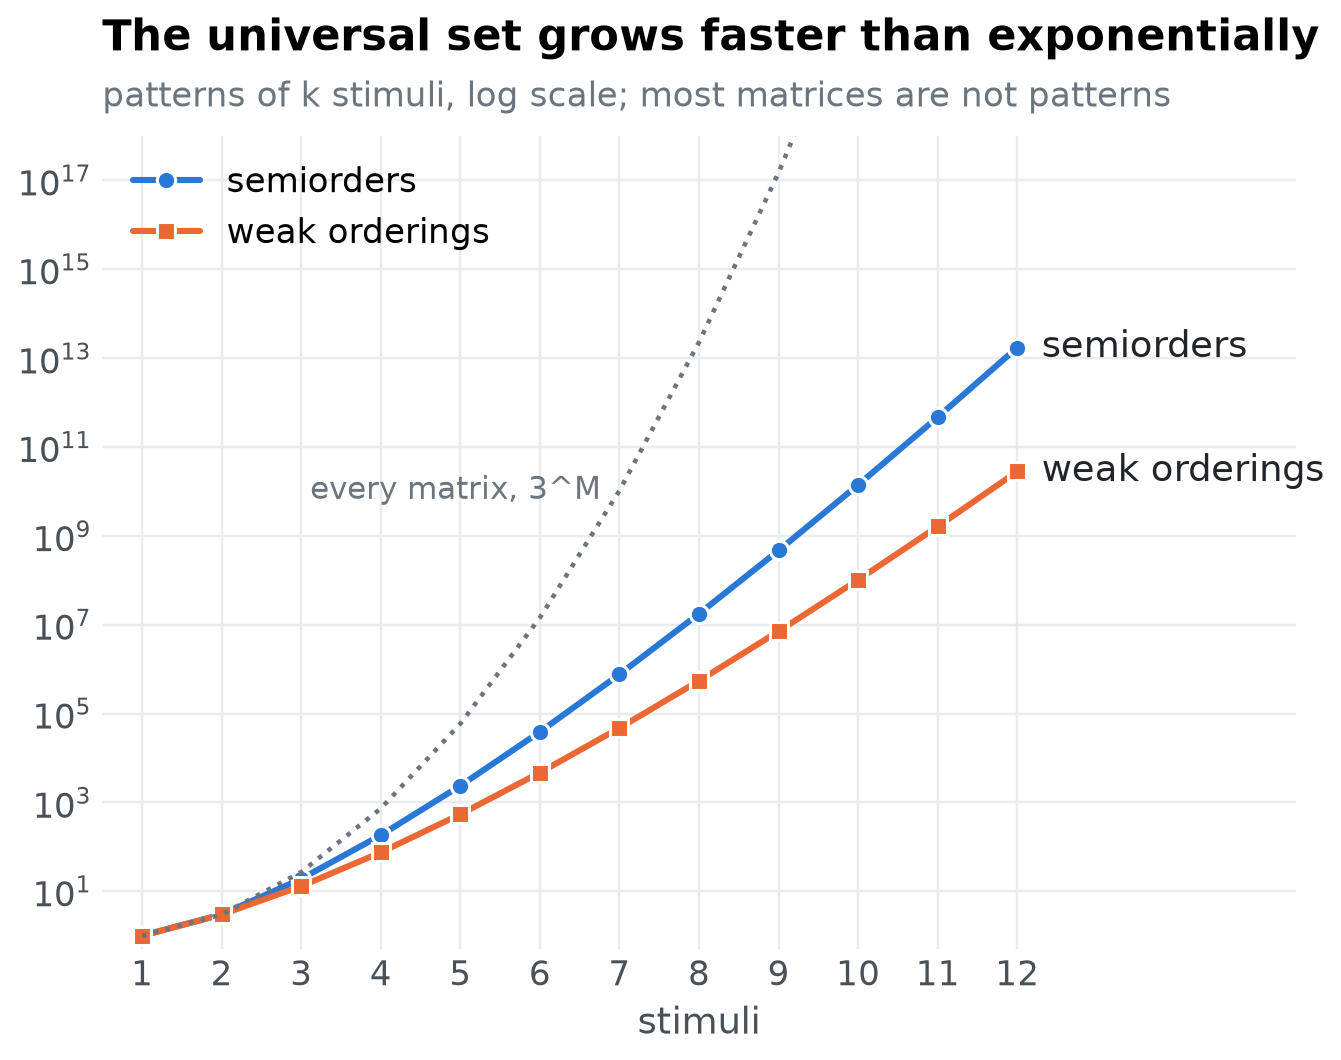

In [9]:
k = np.arange(1, 13)
fig, ax = plt.subplots(figsize=(7, 4.8))
for name, count, colour, marker in [("semiorders", clobe.semiorders, blue, "o"),
                                    ("weak orderings", clobe.fubini, orange, "s")]:
    values = [count(int(n)) for n in k]
    ax.plot(k, values, "-" + marker, color=colour, linewidth=2, markersize=6,
            markeredgecolor="white", label=name)
    ax.annotate(name, (k[-1], values[-1]), xytext=(8, 0), textcoords="offset points",
                color=ink, va="center")
ax.plot(k, 3.0 ** (k * (k - 1) / 2), ":", color=muted, linewidth=1.5)
ax.annotate("every matrix, 3^M", (7, 3.0 ** 21), xytext=(-6, 0), textcoords="offset points",
            color=muted, ha="right", va="center", fontsize=10)
ax.set_yscale("log")
ax.set(xticks=k, xlim=(0.5, 15.5), ylim=(0.5, 1e18), xlabel="stimuli")
ax.legend(loc="upper left")
titled(ax, "The universal set grows faster than exponentially",
       "patterns of k stimuli, log scale; most matrices are not patterns")
show(fig, "growth")

Semiorders outnumber weak orderings, because they also include the non-transitive "about the same" chains, and both grow faster than exponentially. With 8 stimuli there are over 17 million semiorders.

In R, the counts are doubles, which hold whole numbers exactly only up to $2^{53} \approx 9 \times 10^{15}$, so the R functions warn from 17 stimuli for `fubini()` and 14 for `semiorders()`. Here the counts are Python integers, which have no limit, so they are exact however many stimuli there are:

In [10]:
clobe.semiorders(30), clobe.semiorders(30) > 2**53

(13977223809217503353398375258316496402242148303, True)

## When the measurement scale matters

`semiorders(n)` assumes that any values at all could be measured. Real data are often coarser: a proportion of 20 trials can only be 0, 0.05, 0.10, and so on. Then some semiorders cannot occur. `brutes()` finds out which can, by trying every way of assigning the possible values to the stimuli.

For 4 stimuli, a scale of 0, 0.1, ..., 1 with a threshold of 0.1 produces every semiorder:

In [11]:
scale = torch.arange(11, dtype=torch.float64) / 10
clobe.brutes(scale, 4, (0.1, -0.1), return_matrices=False).n, clobe.semiorders(4)

(183, 183)

For 5 stimuli, it does not:

In [12]:
clobe.brutes(scale, 5, (0.1, -0.1), return_matrices=False).n, clobe.semiorders(5)

(2131, 2371)

### Why some patterns are impossible

The problem is not the range of the scale but its *resolution* relative to the threshold. When the threshold is exactly one step, any two values are either within one step (about the same) or at least two steps apart (different); there is nothing in between. Here is a semiorder of 5 stimuli that such a scale cannot produce:

In [13]:
clobe.imac(torch.tensor([0.0, 3, 6, 4, 2]), (2, -2))

tensor([[ 2., -1., -1., -1.,  0.],
        [ 2.,  2., -1.,  0.,  0.],
        [ 2.,  2.,  2.,  0.,  1.],
        [ 2.,  2.,  2.,  2.,  0.],
        [ 2.,  2.,  2.,  2.,  2.]])

Try to realise it with whole-numbered values and a threshold of 1 (stimuli numbered from 1 here, as in the matrix rows 0 to 4):

- Stimulus 1 is smaller than 2, so they are at least 2 steps apart. Stimulus 5 is about the same as both, so it is within 1 step of each. Both can only hold if 2 is exactly 2 steps above 1, with 5 in the middle: $v_2 = v_1 + 2$, $v_5 = v_1 + 1$.
- In the same way, stimulus 4 is about the same as both 2 and 3, while $2 < 3$, so $v_3 = v_2 + 2$ and $v_4 = v_2 + 1 = v_1 + 3$.
- But then $v_4 - v_5 = 2$, so 4 and 5 are different, while the pattern says they are about the same.

With a threshold of *two* steps there is room in between, and the values $(0, 3, 6, 4, 2)$ above produce the pattern. A wider range of one-step values does not help:

In [14]:
(clobe.brutes(torch.arange(21.0), 5, (1, -1), return_matrices=False).n,
 clobe.brutes(torch.arange(13.0), 5, (2, -2), return_matrices=False).n)

(2131, 2371)

How fine does the scale have to be? For 5 stimuli, the share of the semiorders a scale can produce, as the threshold spans more of its steps (the scale runs from 0 to 10 thresholds, so its range is never what limits it):

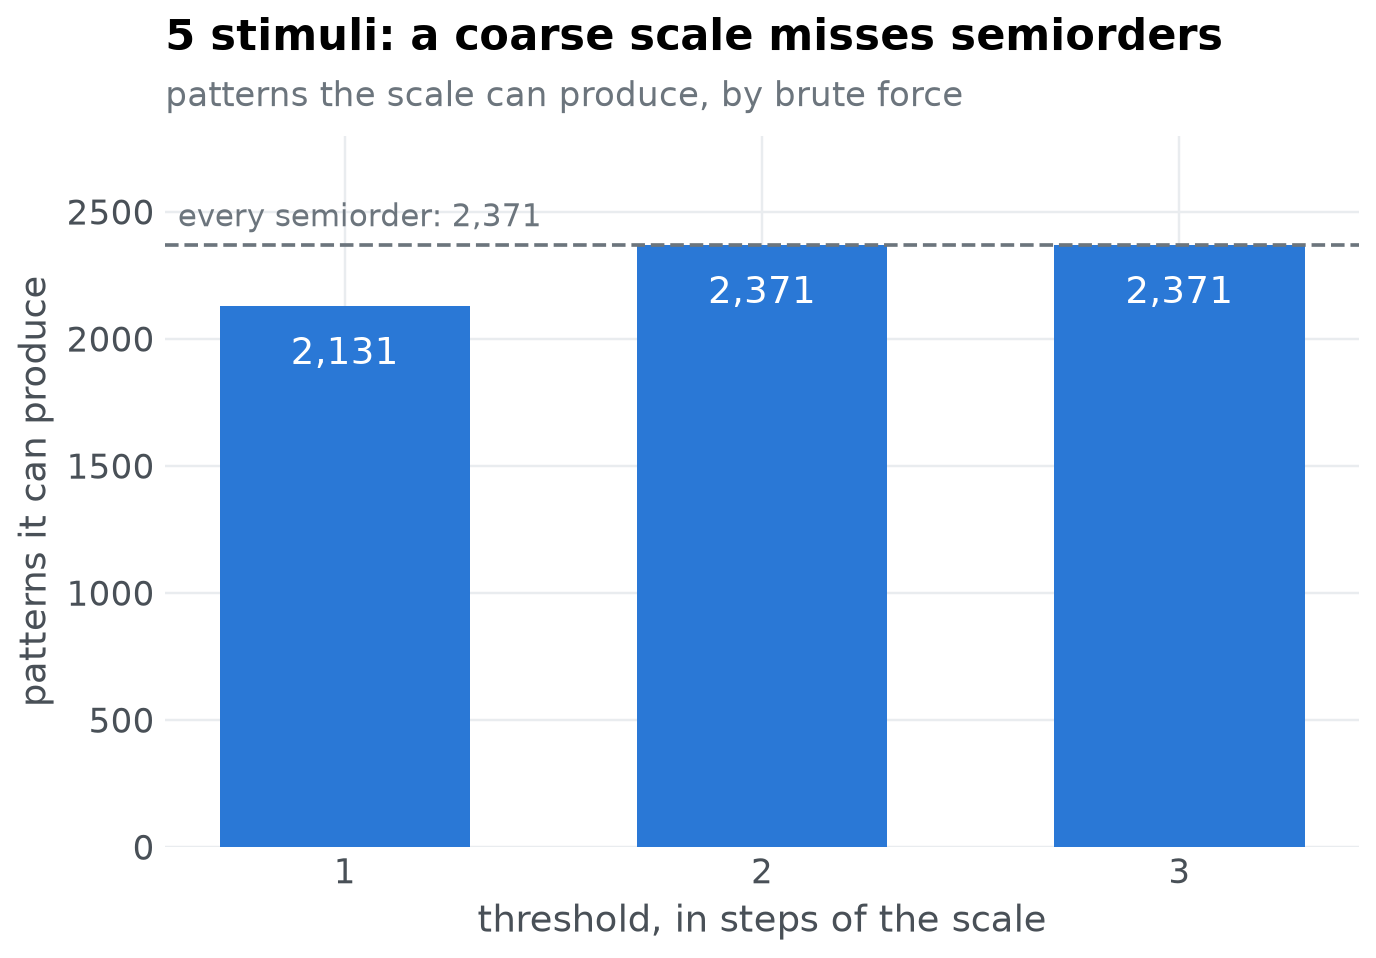

In [15]:
device = "cuda" if torch.cuda.is_available() else "cpu"
steps = [1, 2, 3]
realised = [clobe.brutes(torch.arange(10.0 * t + 1), 5, (t, -t), return_matrices=False,
                         device=device).n for t in steps]
fig, ax = plt.subplots(figsize=(7, 4.2))
bars = ax.bar([str(t) for t in steps], realised, color=blue, width=0.6)
ax.bar_label(bars, labels=[f"{n:,}" for n in realised], padding=-22, color="white")
ax.axhline(clobe.semiorders(5), color=muted, linestyle="--", linewidth=1.2)
ax.annotate(f"every semiorder: {clobe.semiorders(5):,}", (-0.4, clobe.semiorders(5)), xytext=(0, 6),
            textcoords="offset points", color=muted, fontsize=10)
ax.set(ylim=(0, 2800), xlabel="threshold, in steps of the scale", ylabel="patterns it can produce")
titled(ax, "5 stimuli: a coarse scale misses semiorders",
       "patterns the scale can produce, by brute force")
show(fig, "scale-resolution")

So, in practice:

- If the threshold spans several steps of your measurement scale, the universal set is `semiorders(n)` (or `fubini(n)` for weak orderings). You can confirm this with `brutes()`.
- If the threshold is close to a single step, use `brutes()` with the values your scale can actually produce.

## Computing it

`brutes()` evaluates every assignment of values to stimuli: with $m$ possible values and $n$ stimuli, that is $m^n$ assignments. It works through them in chunks of `chunk_size` assignments as tensor operations, on the CPU or, with `device="cuda"`, on the GPU, which is where it is fastest. Even so, $m^n$ grows quickly: 11 values and 8 stimuli is about 214 million assignments; 21 values and 8 stimuli is about 38 billion.

In [16]:
devices = ["cpu"] + (["cuda"] if torch.cuda.is_available() else [])
for device in devices:
    start = time.perf_counter()
    n = clobe.brutes(scale, 7, (0.1, -0.1), return_matrices=False, device=device).n
    print(f"{device}: {scale.numel()}^7 = {scale.numel() ** 7:,} assignments, {n:,} patterns, "
          f"{time.perf_counter() - start:.1f} s")

cpu: 11^7 = 19,487,171 assignments, 437,179 patterns, 0.5 s
cuda: 11^7 = 19,487,171 assignments, 437,179 patterns, 0.0 s


Two arguments help with large problems:

- `return_matrices=False` returns only the count. For 8 stimuli, the matrices alone would take several gigabytes of memory.
- `chunk_size` sets how many assignments are evaluated at once; lower it if the device runs out of memory.

And `orderings()` constructs the patterns directly, so its cost depends on the number of patterns rather than on $m^n$. Use it when every pattern can be measured.

## Appendix A: where the semiorder count comes from

The count of labelled semiorders is the result of Chandon, Lemaire and Pouget (1978), in the form of an exponential generating function given by Stanley (1999, Problem 6.30) and OEIS A006531. This appendix shows how it follows from the two steps of the main text.

**1. Shapes.** Sorted by value, an unlabelled semiorder of $n$ items is fixed by its reach sequence, and there are $C_n$ of those (Wine & Freund, 1957). Write $C(y) = \sum_n C_n y^n$.

**2. Twins.** Two items are *twins* if they relate in the same way to every other item. Merging every set of twins into one item leaves a *twin-free* semiorder, whose items have strictly different values. Let $r_j$ be the number of unlabelled twin-free semiorders of $j$ items, and $R(z) = \sum_j r_j z^j$. Every unlabelled semiorder is a twin-free one with each item replaced by a run of $k \ge 1$ twins, which contributes $y + y^2 + \dots = y / (1 - y)$ for each item, so

$$
C(y) = R\left(\frac{y}{1 - y}\right), \qquad R(z) = C\left(\frac{z}{1 + z}\right).
$$

**3. Labels.** A labelled semiorder of $n$ stimuli is a split of the stimuli into $j$ groups of twins ($S(n, j)$ ways), a twin-free semiorder of $j$ items ($r_j$ ways), and an assignment of the groups to its items ($j!$ ways, as its items are all distinguishable):

$$
s(n) = \sum_{j=0}^{n} S(n, j) \, j! \, r_j .
$$

Since $\sum_n S(n, j) \, x^n / n! = (e^x - 1)^j / j!$, the exponential generating function is

$$
\sum_n s(n) \frac{x^n}{n!} = R(e^x - 1) = C\left(\frac{e^x - 1}{e^x}\right) = C(1 - e^{-x}).
$$

**4. Coefficients.** Expanding $C(1 - e^{-x}) = \sum_j C_j (1 - e^{-x})^j$ and using $(1 - e^{-x})^j = (-1)^j j! \sum_n S(n, j) (-1)^n x^n / n!$, the coefficient of $x^n / n!$ is

$$
s(n) = \sum_{j=0}^{n} (-1)^{n-j} \, C_j \, j! \, S(n, j),
$$

the formula of the main text, which `semiorders()` evaluates in exact integer arithmetic. Weak orderings need no step 2: a weak ordering is a ranking of tied groups, so $\sum_j j! \, S(n, j)$ counts them directly (OEIS A000670), as `fubini()` does.

The counts agree with the published sequences:

In [17]:
oeis_semiorders = [1, 1, 3, 19, 183, 2371, 38703, 763099, 17648823, 468603091]  # OEIS A006531
oeis_weak = [1, 1, 3, 13, 75, 541, 4683, 47293, 545835, 7087261]  # OEIS A000670
assert [clobe.semiorders(n) for n in range(10)] == oeis_semiorders
assert [clobe.fubini(n) for n in range(10)] == oeis_weak
assert [clobe.orderings(n).n for n in range(1, 7)] == oeis_semiorders[1:7]
"the counts match OEIS A006531 and A000670"

'the counts match OEIS A006531 and A000670'

## Appendix B: sources

| Result | Source | Checked against |
|---|---|---|
| Recurrence of the Stirling numbers of the second kind | Graham, Knuth & Patashnik (1994, chap. 6) | OEIS A008277, which states the same recurrence |
| Weak orderings are counted by $\sum_j j! \, S(n, j)$, the Fubini numbers | OEIS A000670 | the sequence and its formula on OEIS; the counts above |
| Unlabelled semiorders are counted by the Catalan numbers | Wine & Freund (1957) | its Crossref record (doi:10.1214/aoms/1177707051), and the attribution in Hu (2014) |
| Labelled semiorders are counted by the coefficients of $C(1 - e^{-x})$ | Chandon, Lemaire & Pouget (1978); Stanley (1999, Problem 6.30) | the Numdam record of Chandon et al.; OEIS A006531, which lists both and gives the formula; the counts above |
| Measurement scales that cannot realise every semiorder | the R package clobe (`vignette("universal-set")`) | `brutes()` in this notebook |

## References

Chandon, J. L., Lemaire, J., & Pouget, J. (1978). Dénombrement des quasi-ordres sur un ensemble fini. *Mathématiques et Sciences Humaines, 62*, 61-80. http://www.numdam.org/item/MSH_1978__62__61_0/

Dome, L., & Wills, A. J. (2025). g-Distance: On the comparison of model and human heterogeneity. *Psychological Review, 132*(3), 632-655. https://doi.org/10.1037/rev0000550

Fishburn, P. C. (1985). *Interval orders and interval graphs: A study of partially ordered sets*. Wiley.

Graham, R. L., Knuth, D. E., & Patashnik, O. (1994). *Concrete mathematics: A foundation for computer science* (2nd ed.). Addison-Wesley.

Hu, Y. (2014). On the number of fixed-length semiorders. *Journal of Integer Sequences, 17*, Article 14.1.6. https://cs.uwaterloo.ca/journals/JIS/VOL17/Hu/hu3.html

OEIS Foundation Inc. (2026). The On-Line Encyclopedia of Integer Sequences: A000670 (Fubini numbers), A006531 (semiorders on n elements), A008277 (Stirling numbers of the second kind). https://oeis.org

Stanley, R. P. (1999). *Enumerative combinatorics* (Vol. 2). Cambridge University Press.

Wine, R. L., & Freund, J. E. (1957). On the enumeration of decision patterns involving n means. *The Annals of Mathematical Statistics, 28*(1), 256-259. https://doi.org/10.1214/aoms/1177707051